**Smoke detection version af `CropCalculatorRandomForrest.ipynb`.** Koden er den samme som originalen; kun data-stien og udvælgelsen af features/target er ændret. Datasæt: `data/smoke_detection_iot.csv`. `Unnamed: 0` (index), `UTC` (tidsstempel) og `CNT` (tæller) er droppet. Features = kun `Temperature[C]`, `Humidity[%]` og `PM2.5` (de tre sensorer i Forest Fire Sensor Network-projektet; alle numeriske, så `cat_attribs` er tom), target = `Fire Alarm`. Split stratificeres på `Fire Alarm` i stedet for `Entity`. Filtret der fjernede Faroe Islands er udkommenteret (findes ikke her). `max_features`-griddet er ændret fra [4, 6, 8] til [1, 2, 3], da der kun er 3 features.

**Note:** `Fire Alarm` er binær (0/1), men modellen er stadig en *regressor* ligesom i originalen. Forudsigelserne er derfor et tal (ca. mellem 0 og 1), og RMSE/MSE/R2/MAE måler hvor tæt det tal er på 0/1. Det er ikke en klassifikations-accuracy.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import SGDRegressor






In [2]:
#df=pd.read_csv("data/cerealCrop.csv")
df=pd.read_csv("data/smoke_detection_iot.csv")
df = df.drop(columns=["Unnamed: 0", "UTC", "CNT"]) # index, tidsstempel og tæller er ikke features
#df = df[df["Entity"] != "Faroe Islands"] # (fjernelse af Faroe Islands giver ikke mening her)
df.head()


,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,Fire Alarm
0,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0
1,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,0
2,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,0
3,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,0
4,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,0


In [3]:
df.shape

(62630, 13)

In [4]:
#list(df.columns)



In [5]:
#train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

#attributes = ["Yield", "Crop_Type", "Fertilizer_Type", "Region", 
#              "N", "P", "K", "pH", "Temperature", "Rainfall"]

strat_train_set, strat_test_set = train_test_split(
    df, 
    test_size=0.2, 
    stratify=df["Fire Alarm"], # Vi sikrer balancen mellem alarm / ikke alarm
    random_state=42
)
attributes = ["Temperature[C]", "Humidity[%]", "PM2.5", "Fire Alarm"]

train_set = strat_train_set[attributes].copy()
test_set = strat_test_set[attributes].copy()

In [6]:
corr_matrix = train_set.corr(numeric_only=True)
print(corr_matrix["Fire Alarm"].sort_values(ascending=False))

Fire Alarm        1.000000
Humidity[%]       0.399020
PM2.5            -0.082061
Temperature[C]   -0.164362
Name: Fire Alarm, dtype: float64


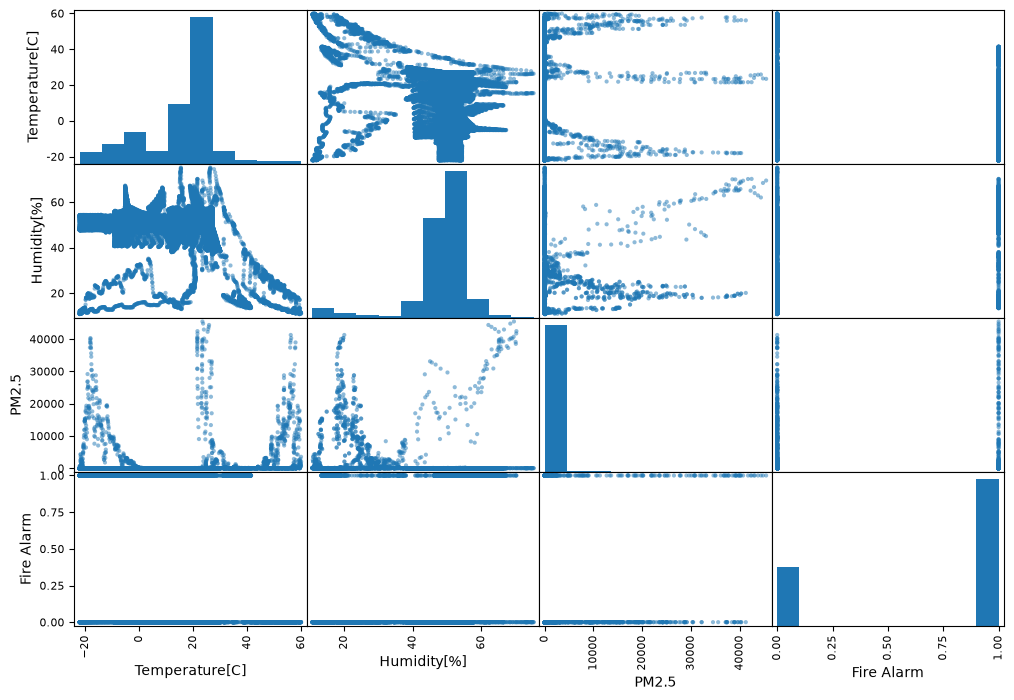

In [7]:
from pandas.plotting import scatter_matrix
attributes = ["Temperature[C]", "Humidity[%]", "PM2.5", "Fire Alarm"]
scatter_matrix(train_set[attributes], figsize=(12, 8))
plt.show()

In [8]:
train_set.head()



,Temperature[C],Humidity[%],PM2.5,Fire Alarm
17799,17.422,51.93,2.03,1
6596,-6.695,55.87,0.66,1
46619,26.950,47.74,2.18,1
41355,24.850,52.23,1.72,1
57343,22.649,40.51,2.00,0


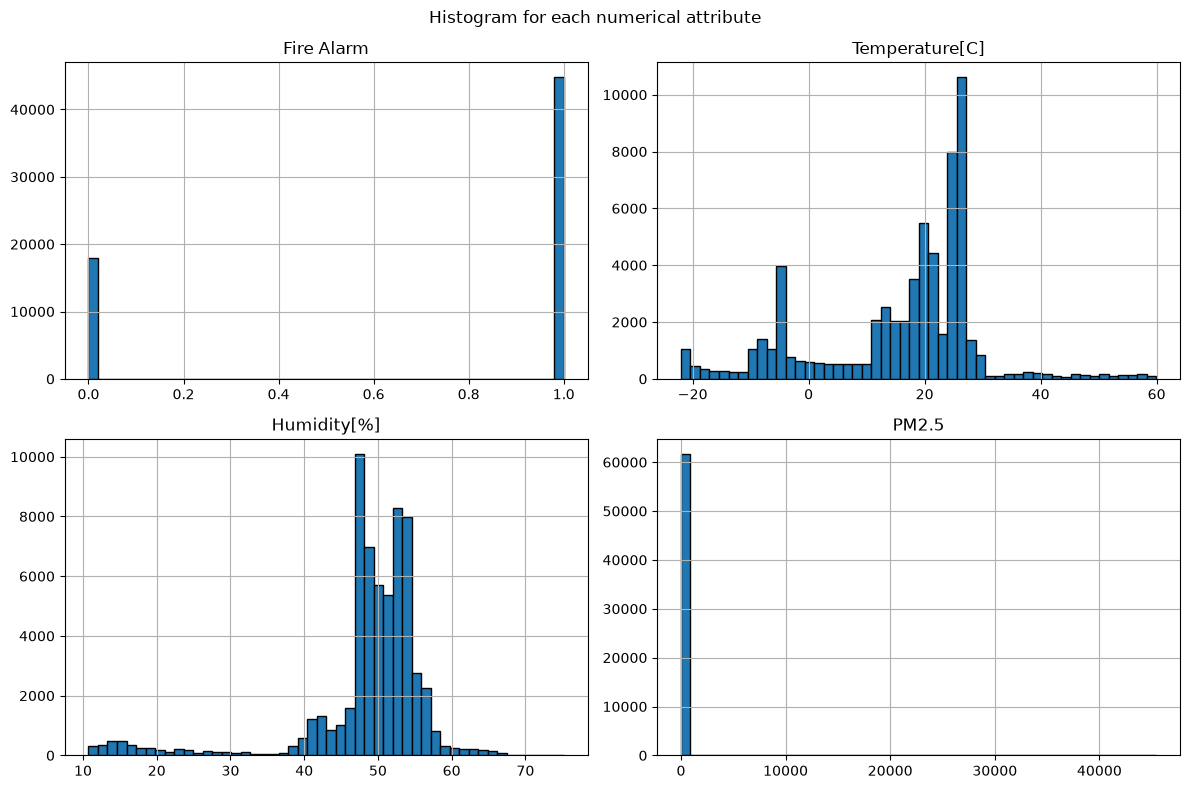

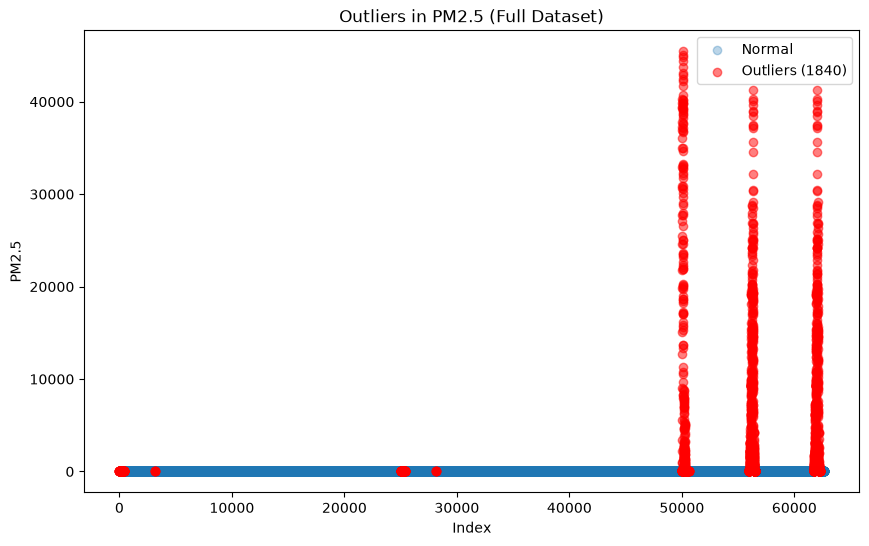

count    62630.000000
mean       184.467770
std       1976.305615
min          0.000000
25%          1.340000
50%          1.880000
75%          2.180000
max      45432.260000
Name: PM2.5, dtype: float64
       Temperature[C]  Humidity[%]     PM2.5  Fire Alarm
50065           23.41        69.47  45432.26           1
50064           23.00        70.28  45018.38           1
50066           23.66        68.41  44786.43           1
50124           25.86        62.03  44357.90           1
50123           25.74        62.93  43765.07           1
50122           25.55        63.95  43094.89           1
50067           23.94        66.57  42939.28           1
50063           21.56        70.19  42450.00           1
50121           25.33        65.03  42242.10           1
50062           21.57        70.14  41715.07           1


In [9]:

# Calculate outliers on full df
Q1 = df["PM2.5"].quantile(0.25)
Q3 = df["PM2.5"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[(df["PM2.5"] < Q1 - 1.5 * IQR) | 
              (df["PM2.5"] > Q3 + 1.5 * IQR)]

normal = df[~df.index.isin(outliers.index)]

# 1. Histogram
df[["Fire Alarm", "Temperature[C]", "Humidity[%]", "PM2.5"]].hist(bins=50, figsize=(12, 8), edgecolor='black')
plt.suptitle("Histogram for each numerical attribute")
plt.tight_layout()
plt.show()

# 2. Scatter with outliers
plt.figure(figsize=(10, 6))
plt.scatter(normal.index, normal["PM2.5"], alpha=0.3, label="Normal")
plt.scatter(outliers.index, outliers["PM2.5"], color='red', alpha=0.5, label=f"Outliers ({len(outliers)})")
plt.xlabel("Index")
plt.ylabel("PM2.5")
plt.title("Outliers in PM2.5 (Full Dataset)")
plt.legend()
plt.show()


print(df["PM2.5"].describe())
print(df.nlargest(10, "PM2.5")[["Temperature[C]", "Humidity[%]", "PM2.5", "Fire Alarm"]])


In [10]:
train_clean = train_set.dropna(subset=["Fire Alarm"]) #y true

X_valueFromMatrix = train_clean.drop("Fire Alarm", axis=1)
Yield_labels = train_clean["Fire Alarm"].copy()


num_attribs = ["Temperature[C]", "Humidity[%]", "PM2.5"]

cat_attribs = [] # ingen kategoriske kolonner i dette datasæt



num_pipeline = make_pipeline(
 SimpleImputer(strategy="median"),
    StandardScaler())

cat_pipeline = make_pipeline(
 SimpleImputer(strategy="most_frequent"),
 OneHotEncoder(handle_unknown="ignore")) #Note skal vi lige undersøge hvad betyder 

#print(X_train_prepared.shape)


preprocessing = ColumnTransformer([
 ("num", num_pipeline, num_attribs),
 ("cat", cat_pipeline, cat_attribs),
])


X_train_prepared = preprocessing.fit_transform(X_valueFromMatrix)

print(X_train_prepared.shape)




(50104, 3)


In [11]:
#tree_reg = make_pipeline(preprocessing, LinearRegression())
#tree_reg.fit(X_valueFromMatrix, Yield_labels)
tree_reg = make_pipeline(preprocessing, RandomForestRegressor(random_state=42))
tree_reg.fit(X_valueFromMatrix, Yield_labels)

#tree_reg = make_pipeline(preprocessing,SGDRegressor(max_iter=1000, tol=1e-3, penalty=None, eta0=0.00001, random_state=42))
#tree_reg.fit(X_valueFromMatrix, Yield_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Temperature[C]','Humidity[%]','PM2.5']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatena

In [12]:
from sklearn.metrics import mean_squared_error
import numpy as np

test_clean = test_set.dropna(subset=["Fire Alarm"])
X_test = test_clean.drop("Fire Alarm", axis=1)
y_test = test_clean["Fire Alarm"].copy()

yield_predictions = tree_reg.predict(X_test)

tree_mse = mean_squared_error(y_test, yield_predictions)
tree_rmse = np.sqrt(tree_mse)

print(f"Modellens gennemsnitlige fejl før finetuning (RMSE): {tree_rmse}")

Modellens gennemsnitlige fejl før finetuning (RMSE): 0.09414251615628122


In [13]:
tree_rmses = -cross_val_score(tree_reg, X_valueFromMatrix, Yield_labels,
 scoring="neg_root_mean_squared_error", cv=10)

pd.Series(tree_rmses).describe()

count    10.000000
mean      0.094318
std       0.005824
min       0.083920
25%       0.091762
50%       0.093538
75%       0.099237
max       0.102170
dtype: float64

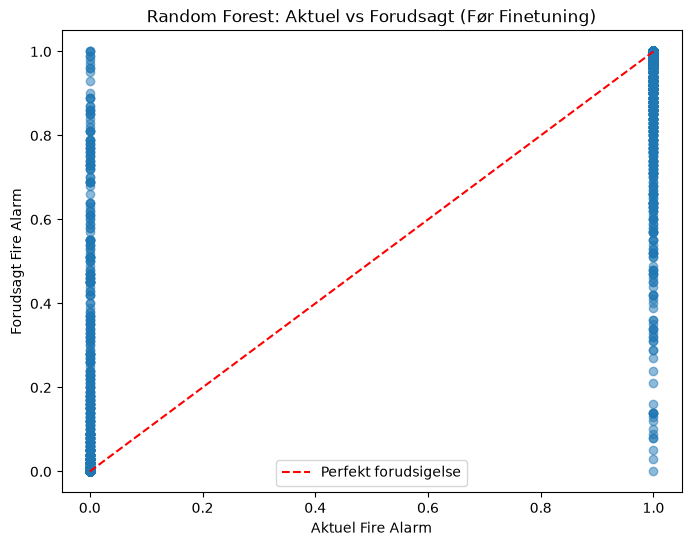

In [14]:
test_clean = test_set.dropna(subset=["Fire Alarm"])
X_test = test_clean.drop("Fire Alarm", axis=1)
y_test = test_clean["Fire Alarm"].copy()

yield_predictions = tree_reg.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, yield_predictions, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Perfekt forudsigelse")
plt.xlabel("Aktuel Fire Alarm")
plt.ylabel("Forudsagt Fire Alarm")
plt.title("Random Forest: Aktuel vs Forudsagt (Før Finetuning)")
plt.legend()
plt.show()

In [15]:
print(Yield_labels.mean())


0.7146335621906434


In [16]:

print(RandomForestRegressor().get_params())


{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}


In [17]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline


full_pipeline = Pipeline([
 ("preprocessing", preprocessing),
 ("random_forest", RandomForestRegressor(random_state=42)),
])
param_grid = [
    {
        'random_forest__n_estimators': [30, 100, 150], 
        'random_forest__max_features': [1, 2, 3], # [4, 6, 8] i originalen - der er kun 3 features nu
        'random_forest__max_depth': [None, 10, 20],
        'random_forest__min_samples_leaf': [1, 2, 4]
    },
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=5,
 scoring='neg_root_mean_squared_error', n_jobs=-1) # n_jobs=-1 kun for hastighed
grid_search.fit(X_valueFromMatrix, Yield_labels)


cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)



In [18]:

columns_to_show = [
    "param_random_forest__n_estimators", 
    "param_random_forest__max_features", 
    "mean_test_score",
] 

cv_res.head() 
print(cv_res[columns_to_show].head())

    param_random_forest__n_estimators  param_random_forest__max_features  \
11                                150                                  2   
10                                100                                  2   
65                                150                                  2   
20                                150                                  3   
64                                100                                  2   

    mean_test_score  
11        -0.096126  
10        -0.096311  
65        -0.096888  
20        -0.096942  
64        -0.096977  


In [19]:
from sklearn.metrics import mean_squared_error
test_clean = test_set.dropna(subset=["Fire Alarm"])

X_test = test_clean.drop("Fire Alarm", axis=1)
y_test = test_clean["Fire Alarm"].copy()

final_model = grid_search.best_estimator_


final_predictions = final_model.predict(X_test)

final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)

print(f"Din endelige test-RMSE er: {final_rmse:.4f}")

Din endelige test-RMSE er: 0.0938


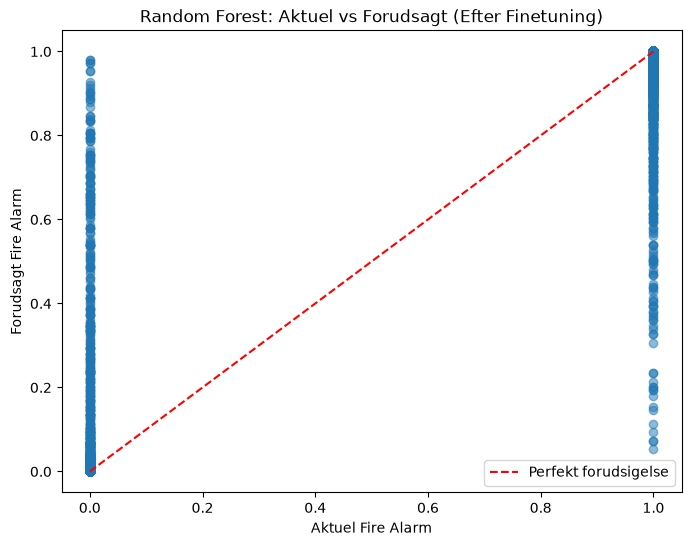

In [20]:
final_predictions = final_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_predictions, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Perfekt forudsigelse")
plt.xlabel("Aktuel Fire Alarm")
plt.ylabel("Forudsagt Fire Alarm")
plt.title("Random Forest: Aktuel vs Forudsagt (Efter Finetuning)")
plt.legend()
plt.show()